In [1]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns
import numpy as np

from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import confusion_matrix, precision_score
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
import torch
import torch.nn as nn

from src.modelos import MLP_clasificacion
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion_binaria
from src.utils import df_features_to_numpy, df_target_to_numpy, make_dataloaders, grid_search_rf_clasificacion, evaluar_modelo_rf_clasificacion, grid_search_xgb_aceptacion, evaluar_modelo_xgb_aceptacion, run_grid_search_pytorch_aceptacion, run_experiment_pytorch_aceptacion
from src.graficos import plot_confusion_matrix, plot_learning_curves_logistic_regression, plot_comparacion_metricas, plot_aceptacion_subplots
from src.splitting import split_estratificado_autor
from src.features import crear_codificador_categorico, transformar_features_categoricas, calcular_antiguedad_autor

# Cargo el dataset ya procesado

In [3]:
#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_train:
    chunk_list.append(chunk)
df_train = pd.concat(chunk_list, ignore_index=True)

#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_val:
    chunk_list.append(chunk)
df_val = pd.concat(chunk_list, ignore_index=True)

#LEO TEST
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_test:
    chunk_list.append(chunk)
df_test = pd.concat(chunk_list, ignore_index=True)

## Preparacion de los datos
Al darnos cuenta de que la poca cantidad de datos de algunas clases no nos permitia hacer buenas predicciones, decidimos intentar otro metodo: clasificar el libro segun si va a ser aceptado por el publico (rating > 3.5) o no. Este podria ser un modelo muy usado por las editoriales, para decidir si aceptar un manuscrito, por ejemplo. <br> <br>
Para este modelo, vamos a seguir la logica de las otras predicciones, es decir:
- definir un baseline
- mejorar los modelos pero no las features
- mejorar los modelos y las features

In [4]:
#features que no van a ser usadas
df_train = df_train.drop(columns = ["description", "title", "language_code", "ratings_count", "authors", "format_group", "genres", "title_key", "title_text"])
df_val = df_val.drop(columns = ["description", "title", "language_code", "ratings_count", "authors", "format_group", "genres", "title_key", "title_text"])

In [5]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features_base = ["is_series", "publication_year", "num_pages", 'AUDIO', 'COMIC', 'EBOOK', 'HARDCOVER', 'OTHER', 'PAPERBACK', "language_code_ang", "language_code_en", "language_code_en-CA", "language_code_en-GB", "language_code_en-US", "language_code_eng", "language_code_enm", "language_code_gem", "language_code_sco", "cantidad_generos"] + generos

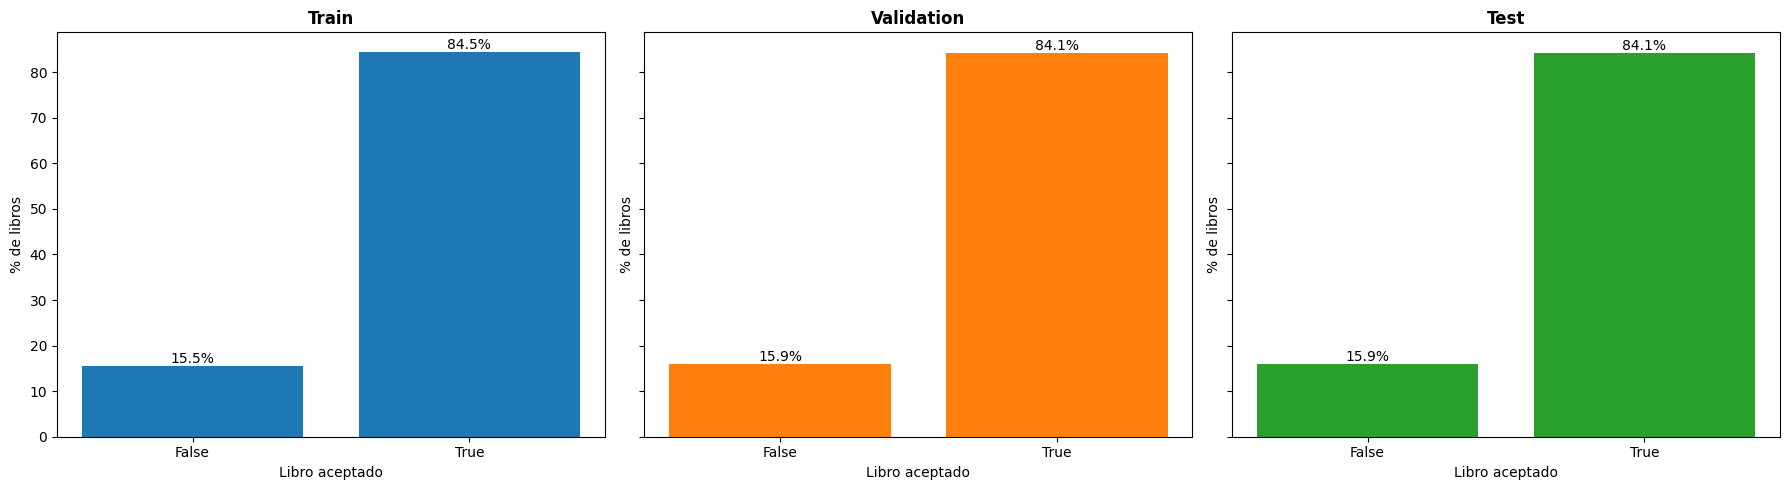

In [6]:
def clasificar_aceptacion(rating):
    return rating > 3.5
    
df_train["aceptado"] = df_train["average_rating"].apply(clasificar_aceptacion)
df_val["aceptado"] = df_val["average_rating"].apply(clasificar_aceptacion)
df_test["aceptado"] = df_test["average_rating"].apply(clasificar_aceptacion)

plot_aceptacion_subplots(df_train, df_val, df_test)

# Modelo base con features base

In [7]:
#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train, y_val, y_test = df_target_to_numpy("aceptado", dfs)
X_train, X_val, X_test = df_features_to_numpy(features_base, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
X_test_scaled = scaler.transform(X_test)

## Sin rebalanceo

,Train,Validation
Accuracy,0.845098,0.841335
Precision,0.845139,0.841378
Recall,0.999923,0.999913
F1,0.916039,0.913820


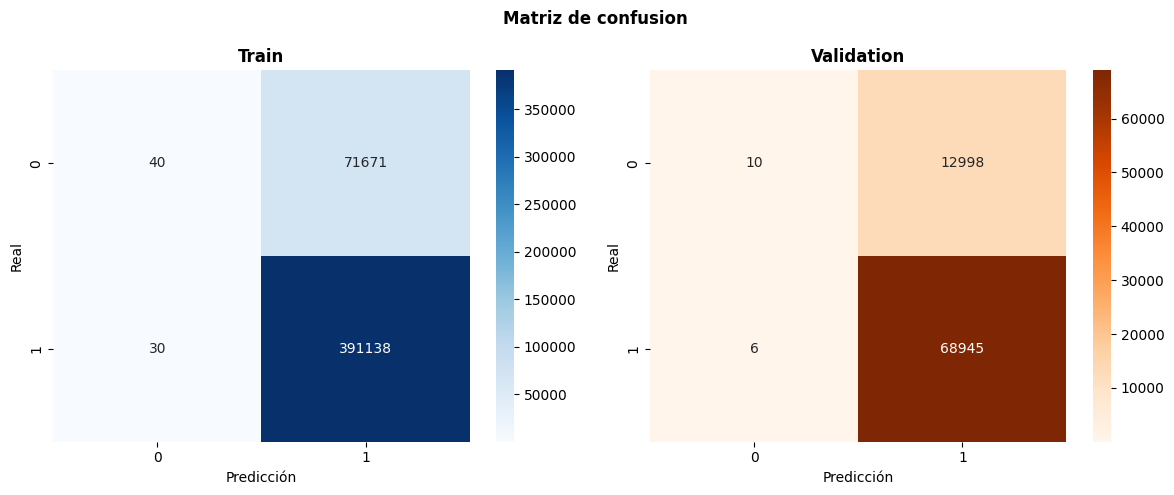

In [8]:
modeloBaseRegresionLogistica = LogisticRegression(max_iter = 1000)
modeloBaseRegresionLogistica.fit(X_train_scaled, y_train)

y_pred_train_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_val_scaled)

metricas_train_base = evaluar_metricas_clasificacion_binaria(y_pred_train_modeloBaseRegresionLogistica, y_train)
metricas_val_base = evaluar_metricas_clasificacion_binaria(y_pred_val_modeloBaseRegresionLogistica, y_val)
tabla_metricas_regresion_logistica_base = tabla_metricas(metricas_train_base, metricas_val_base, ["Accuracy", "Precision", "Recall", "F1"])
display(tabla_metricas_regresion_logistica_base)

labels = [0, 1]
cm_train = confusion_matrix(y_train, y_pred_train_modeloBaseRegresionLogistica, labels = labels)
cm_val = confusion_matrix(y_val, y_pred_val_modeloBaseRegresionLogistica, labels = labels)
plot_confusion_matrix(cm_train, cm_val, labels)

## Con rebalanceo predeterminado de scikit learn

,Train,Validation
Accuracy,0.616846,0.610500
Precision,0.905993,0.902934
Recall,0.609886,0.601703
F1,0.729020,0.722165


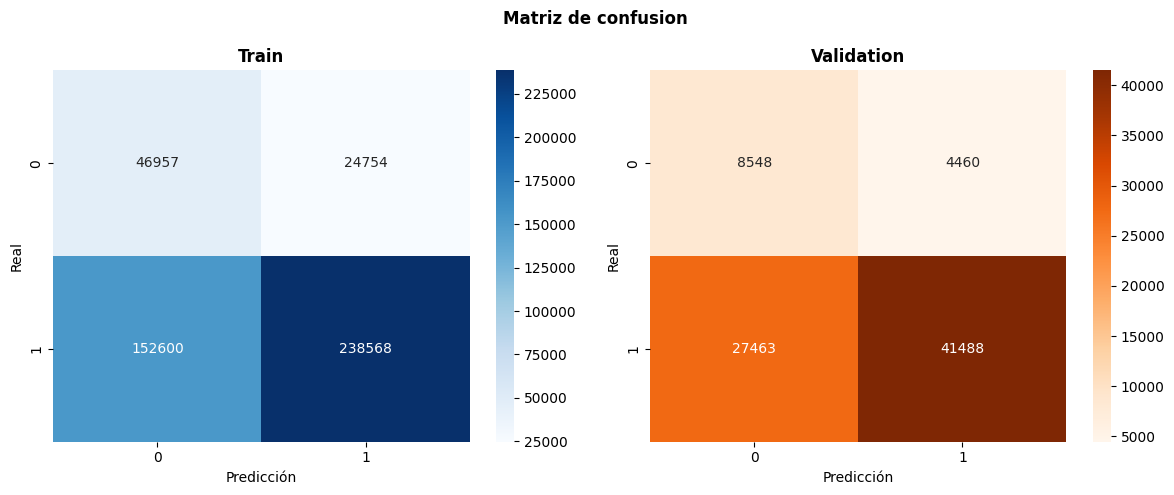

In [9]:
rebalanceo_1 = LogisticRegression(max_iter = 1000, class_weight = "balanced")
rebalanceo_1.fit(X_train_scaled, y_train)

y_pred_train_rebalanceo_1 = rebalanceo_1.predict(X_train_scaled)
y_pred_val_rebalanceo_1 = rebalanceo_1.predict(X_val_scaled)

metricas_train_balanced = evaluar_metricas_clasificacion_binaria(y_pred_train_rebalanceo_1, y_train)
metricas_val_balanced = evaluar_metricas_clasificacion_binaria(y_pred_val_rebalanceo_1, y_val)
tabla_metricas_regresion_logistica_1 = tabla_metricas(metricas_train_balanced, metricas_val_balanced, ["Accuracy", "Precision", "Recall", "F1"])
display(tabla_metricas_regresion_logistica_1)

cm_train = confusion_matrix(y_train, y_pred_train_rebalanceo_1, labels = labels)
cm_val = confusion_matrix(y_val, y_pred_val_rebalanceo_1, labels = labels)
plot_confusion_matrix(cm_train, cm_val, labels)

## Con pesos personalizados

En el contexto de este modelo, quiero que cuando decida que un libro es aceptado, esto casi siempre sea asi. Es por esto que voy a valorizar la metrica de Precision.

,Train,Validation
Accuracy,0.786426,0.782550
Precision,0.871155,0.868094
Recall,0.876979,0.874389
F1,0.874057,0.871230


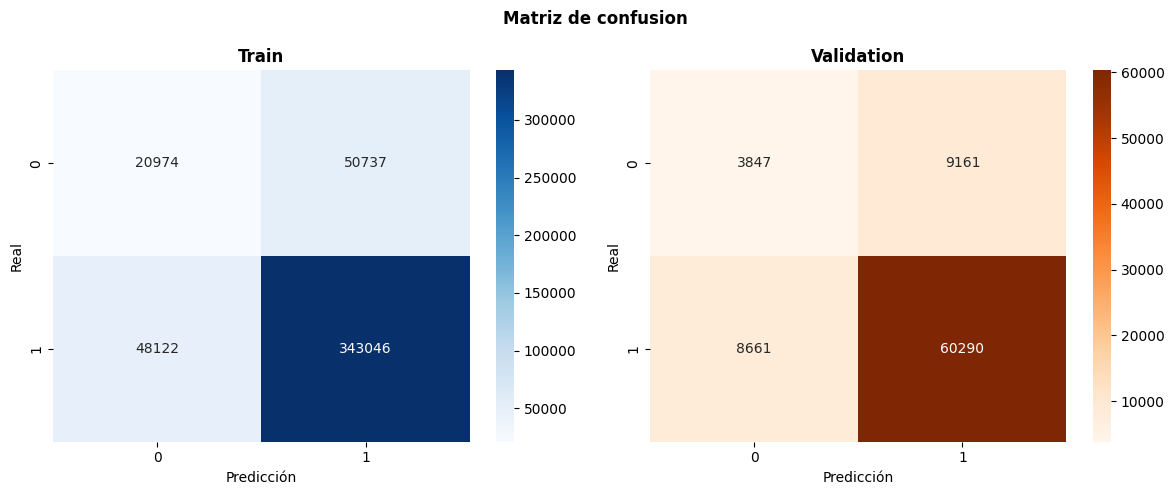

In [10]:
rebalanceo_2 = LogisticRegression(max_iter = 1000, class_weight = {0:3, 1:1})
rebalanceo_2.fit(X_train_scaled, y_train)

y_pred_train_rebalanceo_2 = rebalanceo_2.predict(X_train_scaled)
y_pred_val_rebalanceo_2 = rebalanceo_2.predict(X_val_scaled)

metricas_train_manual = evaluar_metricas_clasificacion_binaria(y_pred_train_rebalanceo_2, y_train)
metricas_val_manual = evaluar_metricas_clasificacion_binaria(y_pred_val_rebalanceo_2, y_val)
tabla_metricas_regresion_logistica_2 = tabla_metricas(metricas_train_manual, metricas_val_manual, ["Accuracy", "Precision", "Recall", "F1"])
display(tabla_metricas_regresion_logistica_2)

cm_train = confusion_matrix(y_train, y_pred_train_rebalanceo_2, labels = labels)
cm_val = confusion_matrix(y_val, y_pred_val_rebalanceo_2)
plot_confusion_matrix(cm_train, cm_val, labels)

## Con undersampling + pesos personalizados

,Train,Validation
Accuracy,0.810117,0.807355
Precision,0.864035,0.861047
Recall,0.920093,0.919378
F1,0.891183,0.889257


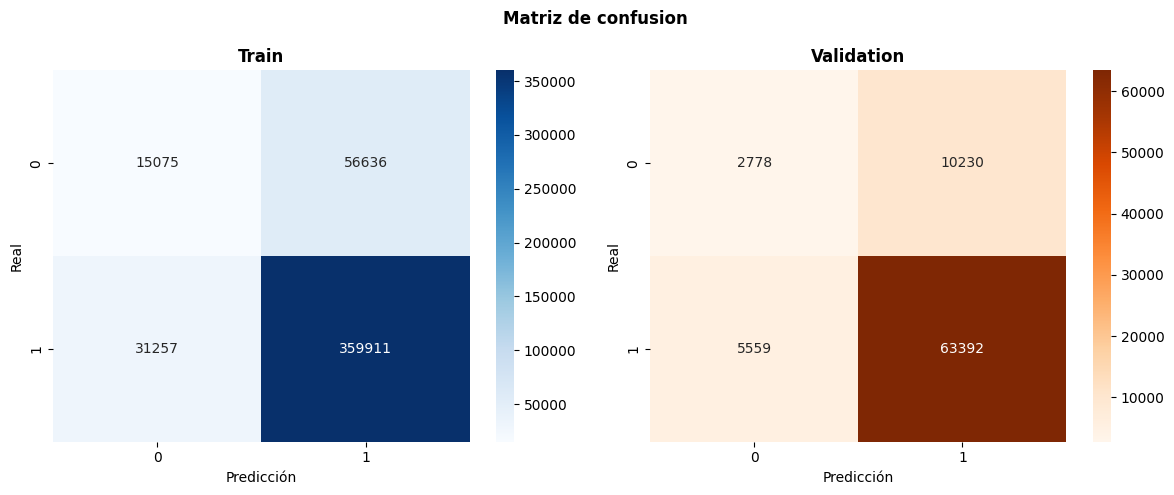

In [11]:
undersampling = RandomUnderSampler(sampling_strategy = {1: 300000}, random_state = 42)
X_res, y_res = undersampling.fit_resample(X_train, y_train) 

scaler = StandardScaler()
X_res_scaled = scaler.fit_transform(X_res)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)

rebalanceo_3 = LogisticRegression(class_weight = {0:2, 1:1}, max_iter = 1000)
rebalanceo_3.fit(X_res_scaled, y_res)

y_pred_train_rebalanceo_3 = rebalanceo_3.predict(X_train_scaled)
y_pred_val_rebalanceo_3 = rebalanceo_3.predict(X_val_scaled)

metricas_train_undersampling = evaluar_metricas_clasificacion_binaria(y_pred_train_rebalanceo_3, y_train)
metricas_val_undersampling = evaluar_metricas_clasificacion_binaria(y_pred_val_rebalanceo_3, y_val)
tabla_metricas_regresion_logistica_3 = tabla_metricas(metricas_train_undersampling, metricas_val_undersampling, ["Accuracy", "Precision", "Recall", "F1"])
display(tabla_metricas_regresion_logistica_3)

cm_train = confusion_matrix(y_train, y_pred_train_rebalanceo_3, labels = labels)
cm_val = confusion_matrix(y_val, y_pred_val_rebalanceo_3, labels = labels)
plot_confusion_matrix(cm_train, cm_val, labels)

## Comparacion de rebalanceos

In [12]:
print("REGRESION LOGISTICA")

print("Sin rebalanceo:")
display(tabla_metricas_regresion_logistica_base)

print("Rebalanceo predeterminado de scikit learn:")
display(tabla_metricas_regresion_logistica_1)

print("Rebalanceo con pesos personalizados:")
display(tabla_metricas_regresion_logistica_2)

print("Rebalanceo con pesos personalizados y undersampling:")
display(tabla_metricas_regresion_logistica_3)

REGRESION LOGISTICA
Sin rebalanceo:


,Train,Validation
Accuracy,0.845098,0.841335
Precision,0.845139,0.841378
Recall,0.999923,0.999913
F1,0.916039,0.913820


Rebalanceo predeterminado de scikit learn:


,Train,Validation
Accuracy,0.616846,0.610500
Precision,0.905993,0.902934
Recall,0.609886,0.601703
F1,0.729020,0.722165


Rebalanceo con pesos personalizados:


,Train,Validation
Accuracy,0.786426,0.782550
Precision,0.871155,0.868094
Recall,0.876979,0.874389
F1,0.874057,0.871230


Rebalanceo con pesos personalizados y undersampling:


,Train,Validation
Accuracy,0.810117,0.807355
Precision,0.864035,0.861047
Recall,0.920093,0.919378
F1,0.891183,0.889257


Analizando las metricas, uno podria pensar que las mejores son las del modelo sin rebalanceo, sin embargo, al observar la matriz de confusion notamos que casi no predice la clase 0. Consideramos que la mejor tecnica de rebalanceo es undersampling con cost, es la que vamos a implementar de ahora en adelante. 

# Modelo avanzado con features basicas

In [13]:
#variables que necesito para grid search, tanto para random forest como para xgboost
X_sub, _, y_sub_regresion, _, y_sub_clasificacion, _ = train_test_split(X_train_scaled, y_train, y_train, train_size=100000, stratify=y_train, random_state=42)

parametros_grid_search_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

parametros_grid_search_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

parametros_grid_search_rn = {
    "capas_ocultas": [[64], [128], [128, 64], [256, 128]],
    "dropout": [0.0, 0.2, 0.4],
    "lr": [0.01, 0.001, 0.0001],
    "funcion_activacion": [nn.ReLU, nn.LeakyReLU]
}

In [14]:
#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {1: 300000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_train_undersampling, y_train_undersampling = undersampling.fit_resample(X_train_scaled, y_train) 

#Hago undersampling para el subset usado en grid search
#cantidad de datos * 0,78 (proporcion de 300mil sobre 390mil)
cant_datos_deseada_sub = {1: 56150} 
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub, y_sub_clasificacion) 

In [15]:
pesos_cost = {0:3, 1:1}
pesos_undersampling_cost = {0:2, 1:1}

### Random Forest

              Train  Validation
Accuracy   0.828375    0.830086
Precision  0.857653    0.873289
Recall     0.944033    0.933474
F1         0.898773    0.902379


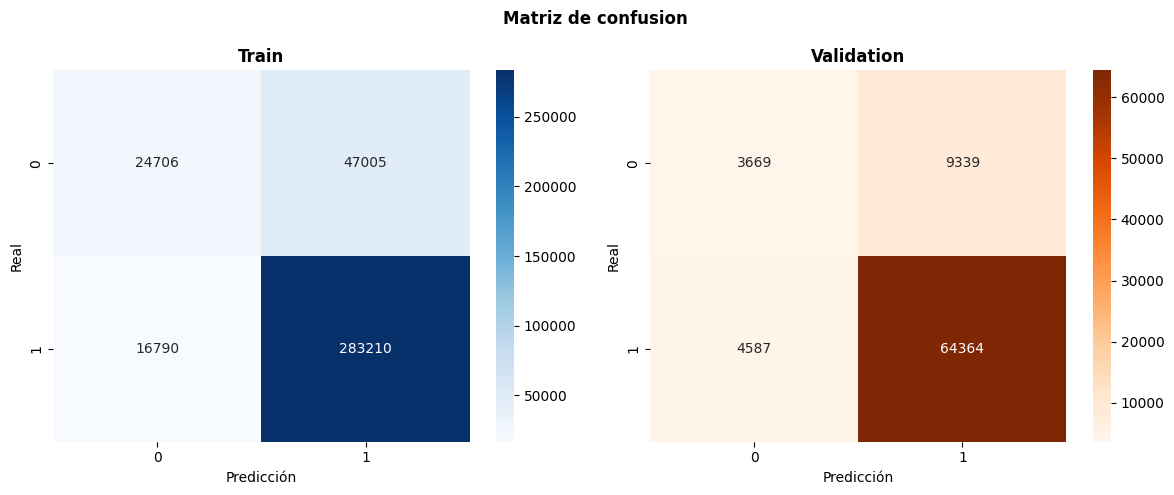

In [16]:
mejores_parametros = grid_search_rf_clasificacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling, parametros_grid_search_rf)
tabla_metricas_rf_clasificacion_undersampling_cost, modeloRandomForestClasificacion, metricas_train_rf, metricas_val_rf = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_scaled, y_val)

### XGBoost

Fitting 3 folds for each of 108 candidates, totalling 324 fits


/home/czava/.local/lib/python3.10/site-packages/xgboost/core.py:751: UserWarning: [11:06:37] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Mejor precision CV: 0.7281120586819451
              Train  Validation
Accuracy   0.798403    0.812492
Precision  0.856925    0.883201
Recall     0.900577    0.895549
F1         0.878209    0.889332


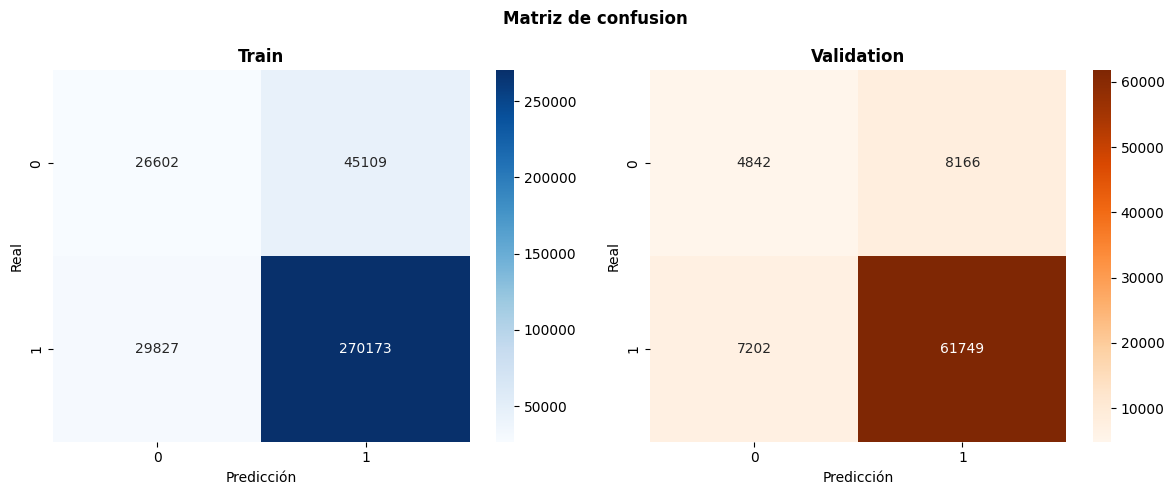

In [17]:
mejores_parametros = grid_search_xgb_aceptacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling, parametros_grid_search_xgb)
tabla_metricas_xgb_clasificacion_undersampling_cost, modeloXGBoostClasificacion, metricas_train_xgb, metricas_val_xgb = evaluar_modelo_xgb_aceptacion(mejores_parametros, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_scaled, y_val)

### Red neuronal

In [18]:
if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"
print(device)

cuda


In [19]:
mejor_precision = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout={dropout}, lr={lr}, activacion={activacion.__name__}")
                modelo = MLP_clasificacion(input_size=X_sub.shape[1], hidden_layers=capas_ocultas, n_classes=2, activation=activacion, dropout=dropout).to(device)

                precision = run_grid_search_pytorch_aceptacion(modelo=modelo, learning_rate=lr, model_name="MLP Clasificacion", X_train=X_sub_undersampling, y_train=y_sub_clasificacion_undersampling, X_val=X_val_scaled, y_val=y_val, device=device, epochs=30, pesos = pesos_undersampling_cost)

                if precision > mejor_precision:
                    mejor_precision = precision
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

Probando: [64], dropout=0.0, lr=0.01, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [00:46<00:00,  1.55s/epoca, epoch=30]


Probando: [64], dropout=0.0, lr=0.01, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:46<00:00,  1.53s/epoca, epoch=30]


Probando: [64], dropout=0.0, lr=0.001, activacion=ReLU


...

Probando: [256, 128], dropout=0.4, lr=0.0001, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [00:45<00:00,  1.53s/epoca, epoch=30]


Probando: [256, 128], dropout=0.4, lr=0.0001, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:47<00:00,  1.58s/epoca, epoch=30]


Mejores parametros: {'capas_ocultas': [128], 'dropout': 0.0, 'lr': 0.01, 'activacion': <class 'torch.nn.modules.activation.ReLU'>}


PyTorch: 100%|██████████| 100/100 [11:27<00:00,  6.88s/epoca, epoch=100]


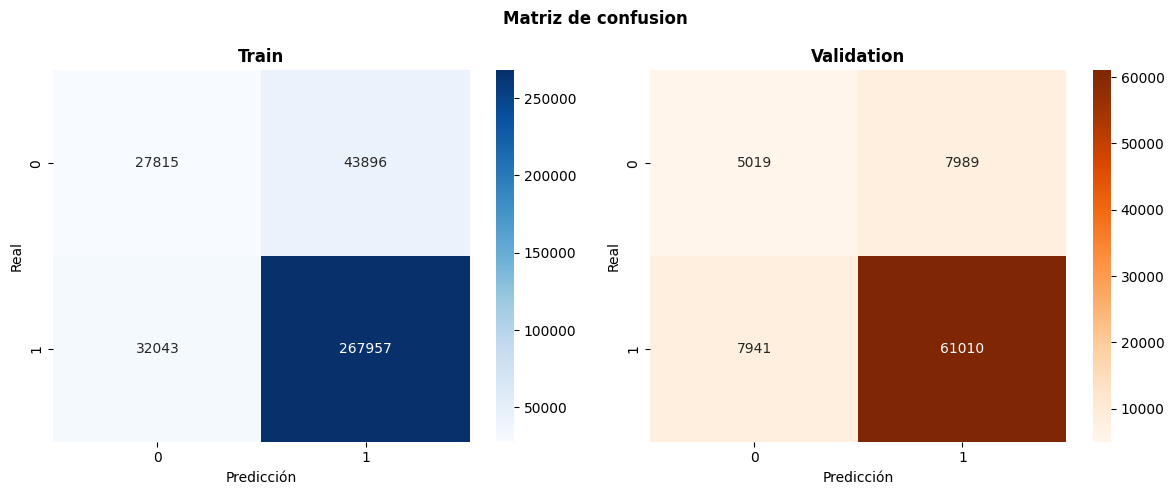

              Train  Validation
Accuracy   0.795704    0.805635
Precision  0.859241    0.884216
Recall     0.893190    0.884831
F1_score   0.875887    0.884523


In [20]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 2, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train_mlp, metricas_val_mlp = run_experiment_pytorch_aceptacion(modelo_clasificacion, "Modelo Clasificacion", X_train_undersampling, y_train_undersampling, X_val_scaled, y_val, device, learning_rate = mejores_parametros["lr"], pesos = pesos_undersampling_cost)
tabla_metricas_mlp_clasificacion_undersampling = tabla_metricas(metricas_train_mlp, metricas_val_mlp, ["Accuracy", "Precision", "Recall", "F1_score"])
print(tabla_metricas_mlp_clasificacion_undersampling)

# Modelo avanzado con features avanzadas

In [21]:
#cargo los embeddings:
descripcion_emb_train = np.load("descripcion_emb_train.npy")
descripcion_emb_val = np.load("descripcion_emb_val.npy")
descripcion_columnas = [ f"description_emb_{i}" for i in range(descripcion_emb_train.shape[1])]
descripcion_emb_train_df = pd.DataFrame(descripcion_emb_train, columns = descripcion_columnas,index=df_train.index)
descripcion_emb_val_df = pd.DataFrame(descripcion_emb_val, columns = descripcion_columnas, index = df_val.index)
df_train = df_train.join(descripcion_emb_train_df)
df_val = df_val.join(descripcion_emb_val_df)

#calculo la feature de antiguedad del autor
df_train = calcular_antiguedad_autor(df_train)
df_val = calcular_antiguedad_autor(df_val)

#Actualizo las features que se usan en esta seccion:
features_avanzadas = (features_base + descripcion_columnas + ["author_antiguedad"])

In [22]:
#Agrego las features engineered que definimos en "ModeloAvanzado_FeaturesAvanzadas":
columnas_categoricas = ["author_id_principal", "publisher"]
codificador = crear_codificador_categorico(df_train, y_train, columnas_categoricas, "aceptado")
X_train = transformar_features_categoricas(df_train, codificador)
X_val = transformar_features_categoricas(df_val, codificador)

#Elimino las variables que no deberia recibir el modelo para entrenar:
columnas_eliminar = ["average_rating", "aceptado", "author_id_principal", "publisher", "estrellas"]
X_train = X_train.drop(columns=columnas_eliminar)
X_val = X_val.drop(columns=columnas_eliminar)

#Y me guardo los nombres de las features, para cuando hagamos el Feature Importance:
columnas_modelo = X_train.columns.tolist()

In [23]:
#Estandarizo los datos:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns = columnas_modelo, index = X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns = columnas_modelo, index = X_val.index)

#Los paso a numpy:
X_train_scaled = X_train_scaled.to_numpy()
X_val_scaled = X_val_scaled.to_numpy()

In [24]:
X_sub, _, _, _, y_sub_clasificacion, _ = train_test_split(X_train_scaled, y_train, y_train, train_size=100000, stratify=y_train, random_state=42)

parametros_grid_search_rf = {
    "n_estimators": [300], #En los 3 coincidio
    "max_depth": [10, 12, 15], 
    "min_samples_split": [2, 5],
    "min_samples_leaf": [5, 10, 15],
    "max_features": ["sqrt"]
}

parametros_grid_search_xgb = {
    "n_estimators": [200, 300],
    "max_depth": [5, 7],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
}

parametros_grid_search_rn = {
    "capas_ocultas": [[128, 64], [256, 128], [256, 128, 64]],
    "dropout": [0.0, 0.2],
    "lr": [0.001, 0.0001],
    "funcion_activacion": [nn.ReLU, nn.LeakyReLU]
}

In [25]:
#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {1: 300000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_train_undersampling, y_train_undersampling = undersampling.fit_resample(X_train_scaled, y_train) 

#Hago undersampling para el subset usado en grid search
cant_datos_deseada_sub = {1: 56150} 
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub, y_sub_clasificacion) 

In [26]:
pesos_cost = {0:3, 1:1}
pesos_undersampling_cost = {0:2, 1:1}

### Random Forest

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Mejores parametros: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 15, 'min_samples_split': 2, 'n_estimators': 300}
Mejor precision CV: 0.8031451499009536
              Train  Validation
Accuracy   0.841799    0.841433
Precision  0.845369    0.862765
Recall     0.983967    0.965019
F1         0.909417    0.911031


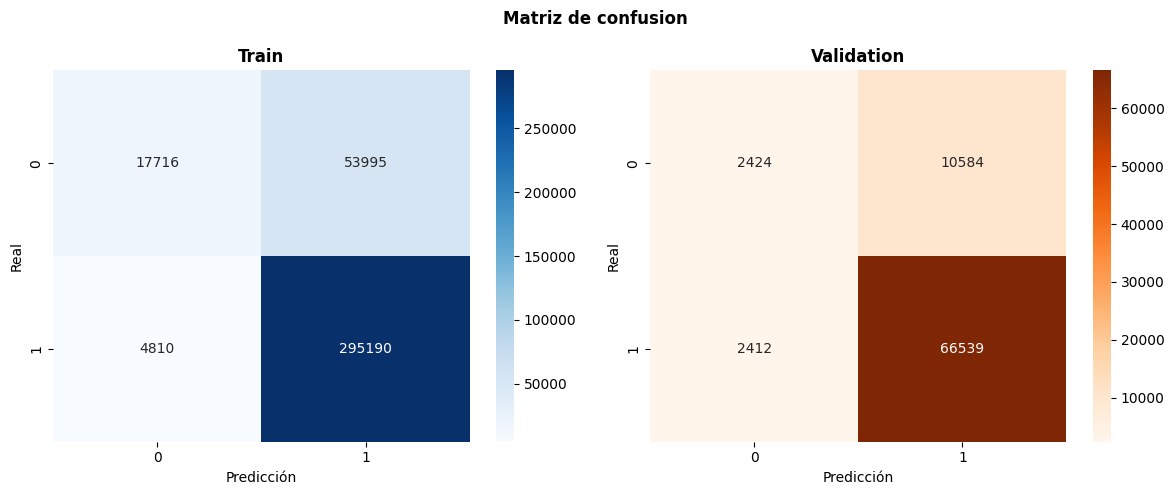

In [27]:
mejores_parametros_rf_mafa = grid_search_rf_clasificacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling, parametros_grid_search_rf)
tabla_metricas_rf_clasificacion_undersampling_cost_mafa, modeloRandomForestClasificacion_mafa, metricas_train_rf_mafa, metricas_val_rf_mafa = evaluar_modelo_rf_clasificacion(mejores_parametros_rf_mafa, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_scaled, y_val)

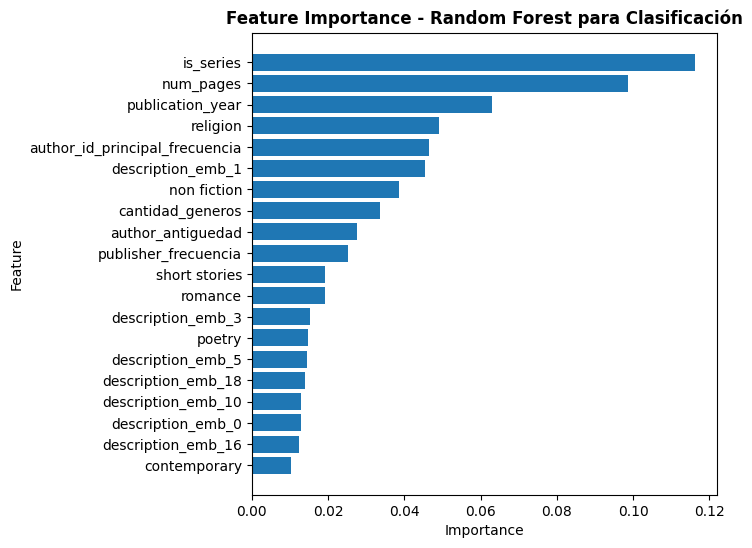

In [28]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": X_train.columns, "importance": modeloRandomForestClasificacion_mafa.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)

### XGBoost

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}
Mejor precision CV: 0.7312601189835646
              Train  Validation
Accuracy   0.811539    0.759331
Precision  0.866112    0.897176
Recall     0.906643    0.806341
F1         0.885914    0.849337


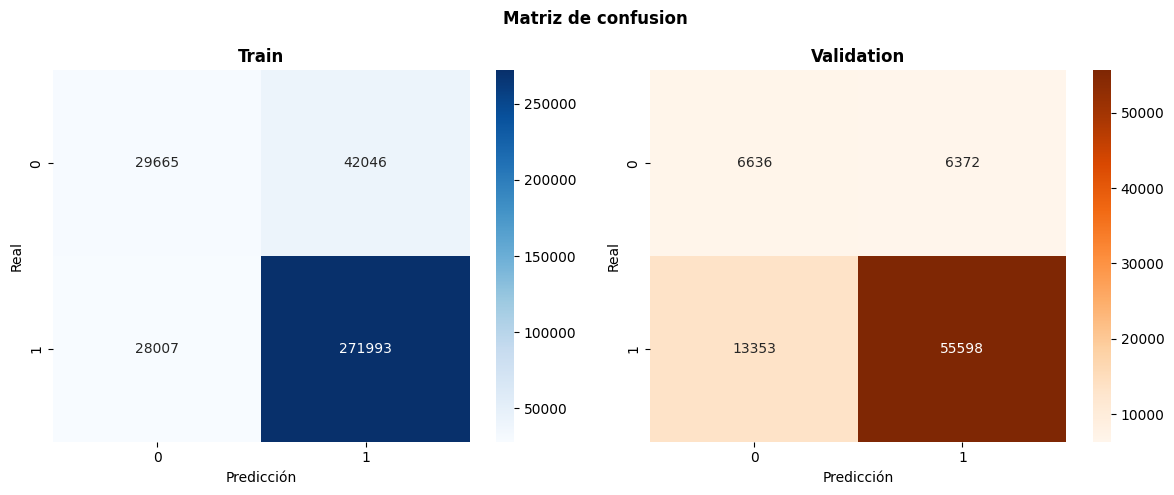

In [29]:
mejores_parametros_xgb_mafa = grid_search_xgb_aceptacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling, parametros_grid_search_xgb)
tabla_metricas_xgb_clasificacion_undersampling_cost_mafa, modeloXGBoostClasificacion_mafa, metricas_train_xgb_mafa, metricas_val_xgb_mafa = evaluar_modelo_xgb_aceptacion(mejores_parametros_xgb_mafa, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_scaled, y_val)

### Red neuronal

In [30]:
mejor_precision = -np.inf
mejores_parametros_mlp_mafa = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout={dropout}, lr={lr}, activacion={activacion.__name__}")
                modelo = MLP_clasificacion(input_size=X_sub.shape[1], hidden_layers=capas_ocultas, n_classes=2, activation=activacion, dropout=dropout).to(device)

                precision = run_grid_search_pytorch_aceptacion(modelo=modelo, learning_rate=lr, model_name="MLP Clasificacion", X_train=X_sub_undersampling, y_train=y_sub_clasificacion_undersampling, X_val=X_val_scaled, y_val=y_val, device=device, epochs=30, pesos = pesos_undersampling_cost)

                if precision > mejor_precision:
                    mejor_precision = precision
                    mejores_parametros_mlp_mafa = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros_mlp_mafa}")

Probando: [128, 64], dropout=0.0, lr=0.001, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [00:39<00:00,  1.32s/epoca, epoch=30]


Probando: [128, 64], dropout=0.0, lr=0.001, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:44<00:00,  1.49s/epoca, epoch=30]


Probando: [128, 64], dropout=0.0, lr=0.0001, activacion=ReLU


...

Probando: [256, 128, 64], dropout=0.2, lr=0.0001, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [00:54<00:00,  1.82s/epoca, epoch=30]


Probando: [256, 128, 64], dropout=0.2, lr=0.0001, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:49<00:00,  1.65s/epoca, epoch=30]



Mejores parametros: {'capas_ocultas': [256, 128, 64], 'dropout': 0.2, 'lr': 0.001, 'activacion': <class 'torch.nn.modules.activation.LeakyReLU'>}


PyTorch: 100%|██████████| 100/100 [09:55<00:00,  5.95s/epoca, epoch=100]


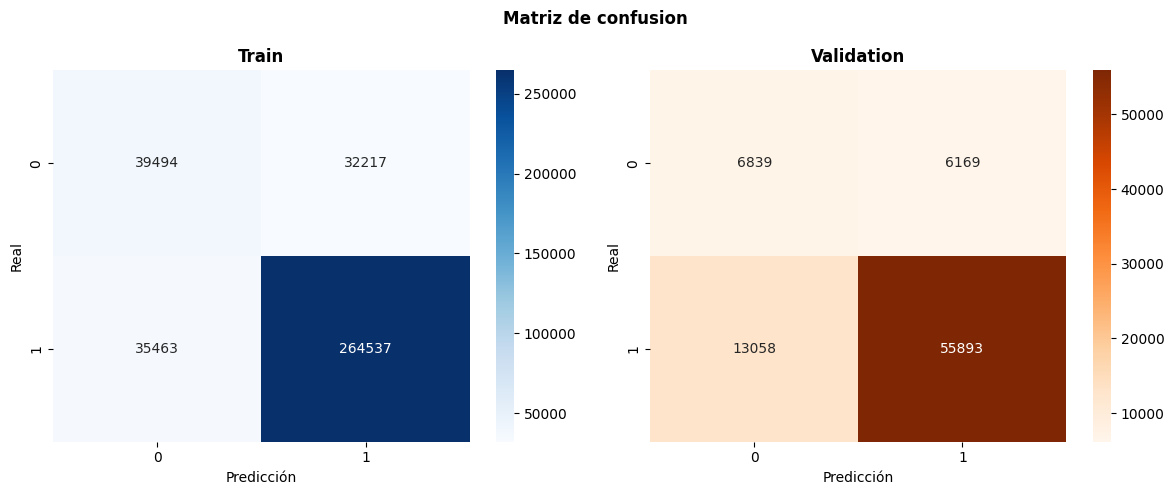

,Train,Validation
Accuracy,0.817923,0.765407
Precision,0.891435,0.900599
Recall,0.881790,0.810619
F1_score,0.886586,0.853244


In [31]:
modelo_clasificacion_mlp_mafa = MLP_clasificacion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros_mlp_mafa["capas_ocultas"], n_classes = 2, activation = mejores_parametros_mlp_mafa["activacion"], dropout = mejores_parametros_mlp_mafa["dropout"]).to(device)
metricas_train_mlp_mafa, metricas_val_mlp_mafa = run_experiment_pytorch_aceptacion(modelo_clasificacion_mlp_mafa, "Modelo Clasificacion", X_train_undersampling, y_train_undersampling, X_val_scaled, y_val, device, learning_rate = mejores_parametros_mlp_mafa["lr"], pesos = pesos_undersampling_cost)
tabla_metricas_mlp_clasificacion_undersampling_mafa = tabla_metricas(metricas_train_mlp_mafa, metricas_val_mlp_mafa, ["Accuracy", "Precision", "Recall", "F1_score"])
display(tabla_metricas_mlp_clasificacion_undersampling_mafa)

In [32]:
print("Comparacion de tablas de metricas:")

print("\nBASELINE:")
print("Regresion logistica: ")
display(tabla_metricas_regresion_logistica_3)

print("\nMODELOS BASE FEATURES AVANZADAS")
print("Random Forest:")
display(tabla_metricas_rf_clasificacion_undersampling_cost)
print("XGBoost:")
display(tabla_metricas_xgb_clasificacion_undersampling_cost)
print("Red Neuronal:")
display(tabla_metricas_mlp_clasificacion_undersampling)

print("\nMODELOS AVANZADOS FEATURES AVANZADAS")
print("Random Forest:")
display(tabla_metricas_rf_clasificacion_undersampling_cost_mafa)
print("XGBoost:")
display(tabla_metricas_xgb_clasificacion_undersampling_cost_mafa)
print("Red Neuronal:")
display(tabla_metricas_mlp_clasificacion_undersampling_mafa)

Comparacion de tablas de metricas:

BASELINE:
Regresion logistica: 


,Train,Validation
Accuracy,0.810117,0.807355
Precision,0.864035,0.861047
Recall,0.920093,0.919378
F1,0.891183,0.889257



MODELOS BASE FEATURES AVANZADAS
Random Forest:


,Train,Validation
Accuracy,0.828375,0.830086
Precision,0.857653,0.873289
Recall,0.944033,0.933474
F1,0.898773,0.902379


XGBoost:


...

,Train,Validation
Accuracy,0.841799,0.841433
Precision,0.845369,0.862765
Recall,0.983967,0.965019
F1,0.909417,0.911031


XGBoost:


,Train,Validation
Accuracy,0.811539,0.759331
Precision,0.866112,0.897176
Recall,0.906643,0.806341
F1,0.885914,0.849337


Red Neuronal:


,Train,Validation
Accuracy,0.817923,0.765407
Precision,0.891435,0.900599
Recall,0.881790,0.810619
F1_score,0.886586,0.853244


# Comparación de modelos y conclusiones

Todos los modelos obtuvieron valores elevados de Precision sobre el conjunto de validacion (superiores a 0.86). Y dado el escenario en el que se utilizaria este modelo, decidimos priorizar esta metrica ya que una editorial estaria mas interesada en que los libros clasificados como "aceptados" (rating > 3.5) realmente pertenezcan a esa categoria, minimizando la cantidad de false positive.

Entre los modelos evaluados, XGBoost con features avanzadas obtuvo una precision de 0.8832 sobre el set de validacion, superando tanto al modelo baseline como a Random Forest. Y si bien la MLP con features avanzadas alcanzo una precision ligeramente superior (0.9006), esta presento una disminucion considerable en Accuracy respecto del entrenamiento, lo que sugiere una menor capacidad de generalizacion. En contraste, XGBoost mantuvo un mejor equilibrio entre Precision, Accuracy (0.8125) y F1-Score (0.8893), ademas de mostrar una diferencia moderada entre entrenamiento y validacion. Es por esto que deicidimos seleccionar al XGBoost con features avanzadas como modelo final para este enfoque, ya que ofrece una alta confiabilidad al identificar libros aceptables sin sacrificar el desempeño general del modelo.
